# UCI HAR: PCA from scratch
Run all cells from top to bottom beside the `UCI HAR Dataset` folder.

This notebook implements PCA with a covariance matrix and eigenvalue decomposition. It reports eigenvalues, eigenvectors and explained variance; plots cumulative variance; and projects the data to two and three components.

Fit scaling and PCA directions on train only and reuse them on test. Activity labels color the visualizations; they do not determine PCA directions. This notebook runs independently of the K-Means notebook.

## 1. Understand the dataset
The local README describes 30 volunteers performing six activities with a smartphone on their waist. Accelerometer and gyroscope readings were collected at 50 Hz. Each example is a 2.56-second window with 50% overlap.

`X_train.txt` and `X_test.txt` already contain 561 extracted features, including means, standard deviations, energy, correlations and frequency measurements. Prefix `t` means time domain and `f` means frequency domain. The values are bounded within [-1, 1]. We use these features rather than the raw 128-reading signals in `Inertial Signals`.

`y_train.txt` and `y_test.txt` contain activity labels. Subject files identify participants; they are not model inputs. The supplied split separates participants, so we keep it.

Dataset source: Anguita et al., *A Public Domain Dataset for Human Activity Recognition Using Smartphones*, ESANN 2013, as cited in the local README.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("UCI HAR Dataset")
OUTPUT_DIR = Path("har_results/pca_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

## 2. Read features, activities and both data splits
Some names in `features.txt` repeat. Adding the feature number gives each column a unique name without dropping any features.

In [2]:
features = pd.read_csv(DATA_DIR / "features.txt", sep=r"\s+", header=None,
                       names=["Number", "Feature"])
activities = pd.read_csv(DATA_DIR / "activity_labels.txt", sep=r"\s+", header=None,
                         names=["Label", "Activity"])
feature_names = features["Number"].astype(str) + "_" + features["Feature"]

X_train = np.loadtxt(DATA_DIR / "train/X_train.txt")
X_test = np.loadtxt(DATA_DIR / "test/X_test.txt")
y_train = np.loadtxt(DATA_DIR / "train/y_train.txt", dtype=int)
y_test = np.loadtxt(DATA_DIR / "test/y_test.txt", dtype=int)
subject_train = np.loadtxt(DATA_DIR / "train/subject_train.txt", dtype=int)
subject_test = np.loadtxt(DATA_DIR / "test/subject_test.txt", dtype=int)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Missing or infinite training values:", np.sum(~np.isfinite(X_train)))
print("Missing or infinite test values:", np.sum(~np.isfinite(X_test)))
print("Subjects shared by train and test:", set(subject_train) & set(subject_test))
display(activities)
display(features.head(10))
display(pd.DataFrame(X_train[:5], columns=feature_names))

Training features: (7352, 561)
Test features: (2947, 561)
Missing or infinite training values: 0
Missing or infinite test values: 0
Subjects shared by train and test: set()


,Label,Activity
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING
5,6,LAYING


,Number,Feature
0,1,tBodyAcc-mean()-X
1,2,tBodyAcc-mean()-Y
2,3,tBodyAcc-mean()-Z
3,4,tBodyAcc-std()-X
4,5,tBodyAcc-std()-Y
5,6,tBodyAcc-std()-Z
6,7,tBodyAcc-mad()-X
7,8,tBodyAcc-mad()-Y
8,9,tBodyAcc-mad()-Z
9,10,tBodyAcc-max()-X


,1_tBodyAcc-mean()-X,2_tBodyAcc-mean()-Y,3_tBodyAcc-mean()-Z,4_tBodyAcc-std()-X,5_tBodyAcc-std()-Y,6_tBodyAcc-std()-Z,7_tBodyAcc-mad()-X,8_tBodyAcc-mad()-Y,9_tBodyAcc-mad()-Z,10_tBodyAcc-max()-X,11_tBodyAcc-max()-Y,12_tBodyAcc-max()-Z,13_tBodyAcc-min()-X,14_tBodyAcc-min()-Y,15_tBodyAcc-min()-Z,16_tBodyAcc-sma(),17_tBodyAcc-energy()-X,18_tBodyAcc-energy()-Y,19_tBodyAcc-energy()-Z,20_tBodyAcc-iqr()-X,21_tBodyAcc-iqr()-Y,22_tBodyAcc-iqr()-Z,23_tBodyAcc-entropy()-X,24_tBodyAcc-entropy()-Y,25_tBodyAcc-entropy()-Z,"26_tBodyAcc-arCoeff()-X,1","27_tBodyAcc-arCoeff()-X,2","28_tBodyAcc-arCoeff()-X,3","29_tBodyAcc-arCoeff()-X,4","30_tBodyAcc-arCoeff()-Y,1","31_tBodyAcc-arCoeff()-Y,2","32_tBodyAcc-arCoeff()-Y,3","33_tBodyAcc-arCoeff()-Y,4","34_tBodyAcc-arCoeff()-Z,1","35_tBodyAcc-arCoeff()-Z,2","36_tBodyAcc-arCoeff()-Z,3","37_tBodyAcc-arCoeff()-Z,4","38_tBodyAcc-correlation()-X,Y","39_tBodyAcc-correlation()-X,Z","40_tBodyAcc-correlation()-Y,Z",...,522_fBodyBodyAccJerkMag-energy(),523_fBodyBodyAccJerkMag-iqr(),524_fBodyBodyAccJerkMag-entropy(),525_fBodyBodyAccJerkMag-maxInds,526_fBodyBodyAccJerkMag-meanFreq(),527_fBodyBodyAccJerkMag-skewness(),528_fBodyBodyAccJerkMag-kurtosis(),529_fBodyBodyGyroMag-mean(),530_fBodyBodyGyroMag-std(),531_fBodyBodyGyroMag-mad(),532_fBodyBodyGyroMag-max(),533_fBodyBodyGyroMag-min(),534_fBodyBodyGyroMag-sma(),535_fBodyBodyGyroMag-energy(),536_fBodyBodyGyroMag-iqr(),537_fBodyBodyGyroMag-entropy(),538_fBodyBodyGyroMag-maxInds,539_fBodyBodyGyroMag-meanFreq(),540_fBodyBodyGyroMag-skewness(),541_fBodyBodyGyroMag-kurtosis(),542_fBodyBodyGyroJerkMag-mean(),543_fBodyBodyGyroJerkMag-std(),544_fBodyBodyGyroJerkMag-mad(),545_fBodyBodyGyroJerkMag-max(),546_fBodyBodyGyroJerkMag-min(),547_fBodyBodyGyroJerkMag-sma(),548_fBodyBodyGyroJerkMag-energy(),549_fBodyBodyGyroJerkMag-iqr(),550_fBodyBodyGyroJerkMag-entropy(),551_fBodyBodyGyroJerkMag-maxInds,552_fBodyBodyGyroJerkMag-meanFreq(),553_fBodyBodyGyroJerkMag-skewness(),554_fBodyBodyGyroJerkMag-kurtosis(),"555_angle(tBodyAccMean,gravity)","556_angle(tBodyAccJerkMean),gravityMean)","557_angle(tBodyGyroMean,gravityMean)","558_angle(tBodyGyroJerkMean,gravityMean)","559_angle(X,gravityMean)","560_angle(Y,gravityMean)","561_angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,-0.567378,-0.744413,0.852947,0.685845,0.814263,-0.965523,-0.999945,-0.999863,-0.994612,-0.994231,-0.987614,-0.943220,-0.407747,-0.679338,-0.602122,0.929294,-0.853011,0.359910,-0.058526,0.256892,-0.224848,0.264106,-0.095246,0.278851,-0.465085,0.491936,-0.190884,0.376314,0.435129,0.660790,...,-0.999918,-0.991364,-1.0,-0.936508,0.346989,-0.516080,-0.802760,-0.980135,-0.961309,-0.973653,-0.952264,-0.989498,-0.980135,-0.999240,-0.992656,-0.701291,-1.000000,-0.128989,0.586156,0.374605,-0.991990,-0.990697,-0.989941,-0.992448,-0.991048,-0.991990,-0.999937,-0.990458,-0.871306,-1.000000,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,-0.557851,-0.818409,0.849308,0.685845,0.822637,-0.981930,-0.999991,-0.999788,-0.998405,-0.999150,-0.977866,-0.948225,-0.714892,-0.500930,-0.570979,0.611627,-0.329549,0.284213,0.284595,0.115705,-0.090963,0.294310,-0.281211,0.085988,-0.022153,-0.016657,-0.220643,-0.013429,-0.072692,0.579382,...,-0.999867,-0.991134,-1.0,-0.841270,0.532061,-0.624871,-0.900160,-0.988296,-0.983322,-0.982659,-0.986321,-0.991829,-0.988296,-0.999811,-0.993979,-0.720683,-0.948718,-0.271958,-0.336310,-0.720015,-0.995854,-0.996399,-0.995442,-0.996866,-0.994440,-0.995854,-0.999981,-0.994544,-1.000000,-1.000000,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,-0.557851,-0.818409,0.843609,0.682401,0.839344,-0.983478,-0.999969,-0.999660,-0.999470,-0.997130,-0.964

,Train,Test
Activity,,
WALKING,1226,496
WALKING_UPSTAIRS,1073,471
WALKING_DOWNSTAIRS,986,420
SITTING,1286,491
STANDING,1374,532
LAYING,1407,537


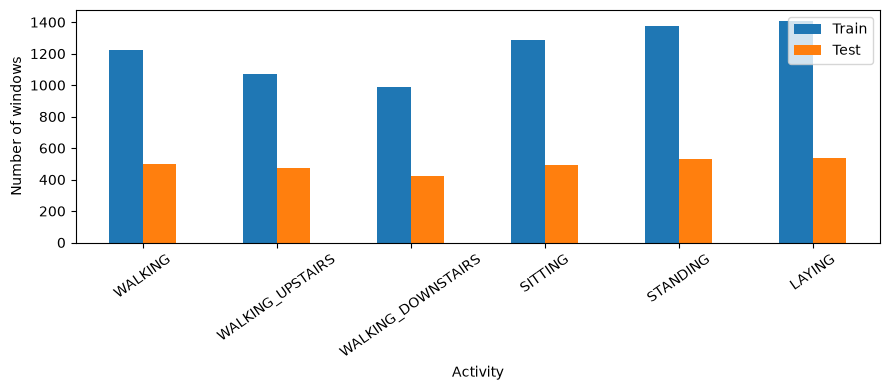

In [3]:
activity_counts = pd.DataFrame({
    "Train": pd.Series(y_train).value_counts(),
    "Test": pd.Series(y_test).value_counts()
}).sort_index()
activity_counts.index = activities["Activity"]
display(activity_counts)
activity_counts.plot(kind="bar", rot=35, figsize=(9, 4))
plt.ylabel("Number of windows")
plt.tight_layout()
plt.show()

## 3. Scale the features
Although features are bounded, their variances differ. Standardization gives each feature unit training variance before calculating distances. Fit the scaler only on train and reuse it for test. This is a modeling choice: it gives low-variance features more weight than the original bounded values would.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 4. Center the training features and calculate covariance
PCA finds directions with the greatest variance. We use standardized features. Fit PCA on train and project test onto the same directions. The covariance matrix records how pairs of features vary together.

In [5]:
pca_mean = X_train_scaled.mean(axis=0)
X_train_centered = X_train_scaled - pca_mean
X_test_centered = X_test_scaled - pca_mean

covariance_matrix = np.cov(X_train_centered, rowvar=False)
print("Covariance matrix shape:", covariance_matrix.shape)
display(pd.DataFrame(covariance_matrix[:5, :5]))

Covariance matrix shape: (561, 561)


,0,1,2,3,4
0,1.000136,0.148082,-0.256987,0.000619,-0.021906
1,0.148082,1.000136,-0.078780,-0.045167,-0.044926
2,-0.256987,-0.078780,1.000136,-0.020220,-0.016643
3,0.000619,-0.045167,-0.020220,1.000136,0.927587
4,-0.021906,-0.044926,-0.016643,0.927587,1.000136


## 5. Eigenvalues and eigenvectors
An eigenvector is a principal direction; its eigenvalue measures variance along that direction. `eigh` works with symmetric matrices such as covariance matrices. Sort from largest eigenvalue to smallest. Each column of `eigenvectors` is a principal direction.

In [6]:
eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Remove tiny negative values caused by numerical rounding.
eigenvalues = np.maximum(eigenvalues, 0)
explained_variance = eigenvalues / eigenvalues.sum()
cumulative_variance = np.cumsum(explained_variance)

pca_summary = pd.DataFrame({
    "Component": np.arange(1, len(eigenvalues) + 1),
    "Eigenvalue": eigenvalues,
    "Explained variance ratio": explained_variance,
    "Cumulative variance": cumulative_variance
})
display(pca_summary.head(10))
print("First two eigenvectors, first ten features:")
display(pd.DataFrame(eigenvectors[:10, :2], index=feature_names[:10], columns=["PC1", "PC2"]))
pca_summary.to_csv(OUTPUT_DIR / "pca_explained_variance.csv", index=False)
np.save(OUTPUT_DIR / "pca_eigenvectors.npy", eigenvectors)

First two eigenvectors, first ten features:


,Component,Eigenvalue,Explained variance ratio,Cumulative variance
0,1,284.921131,0.507812,0.507812
1,2,36.922638,0.065807,0.573619
2,3,15.746252,0.028064,0.601683
3,4,14.049086,0.025040,0.626722
4,5,10.594720,0.018883,0.645605
5,6,9.672992,0.017240,0.662845
6,7,7.692421,0.013710,0.676555
7,8,6.727741,0.011991,0.688546
8,9,5.587532,0.009959,0.698505
9,10,5.414872,0.009651,0.708156


,PC1,PC2
1_tBodyAcc-mean()-X,0.000028,-0.015638
2_tBodyAcc-mean()-Y,-0.002473,0.000080
3_tBodyAcc-mean()-Z,-0.001527,0.004052
4_tBodyAcc-std()-X,0.056213,0.011165
5_tBodyAcc-std()-Y,0.056788,0.025959
6_tBodyAcc-std()-Z,0.054363,0.031240
7_tBodyAcc-mad()-X,0.055969,0.009835
8_tBodyAcc-mad()-Y,0.056264,0.028635
9_tBodyAcc-mad()-Z,0.053886,0.035351
10_tBodyAcc-max()-X,0.055892,0.010926


## 6. Plot cumulative explained variance

Components needed for 90% variance: 63


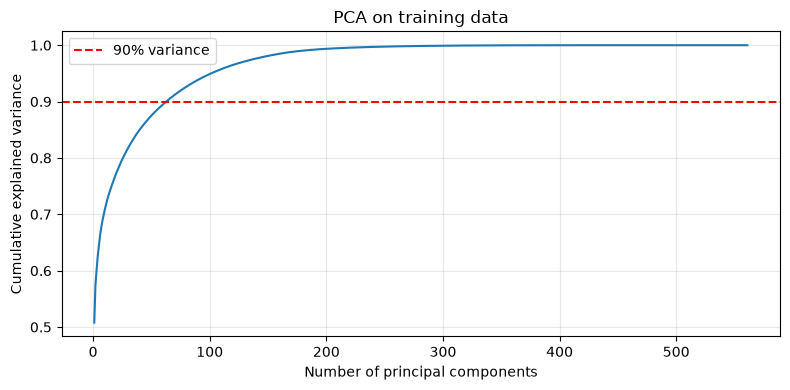

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(pca_summary["Component"], cumulative_variance)
plt.axhline(0.90, color="red", linestyle="--", label="90% variance")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA on training data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pca_cumulative_variance.png", dpi=150)
plt.show()

components_for_90 = np.searchsorted(cumulative_variance, 0.90) + 1
print("Components needed for 90% variance:", components_for_90)

## 7. Reduce to two and three components
Multiply centered features by the first two or three eigenvectors. These coordinates retain only part of the total variance; the printed percentages show how much.

In [8]:
X_train_pca2 = X_train_centered @ eigenvectors[:, :2]
X_test_pca2 = X_test_centered @ eigenvectors[:, :2]
X_train_pca3 = X_train_centered @ eigenvectors[:, :3]
X_test_pca3 = X_test_centered @ eigenvectors[:, :3]

print("2D train / test:", X_train_pca2.shape, X_test_pca2.shape)
print("3D train / test:", X_train_pca3.shape, X_test_pca3.shape)
print("Variance retained by 2 PCs:", round(100 * cumulative_variance[1], 2), "%")
print("Variance retained by 3 PCs:", round(100 * cumulative_variance[2], 2), "%")

pd.DataFrame(X_train_pca3, columns=["PC1", "PC2", "PC3"]).to_csv(OUTPUT_DIR / "train_pca3.csv", index=False)
pd.DataFrame(X_test_pca3, columns=["PC1", "PC2", "PC3"]).to_csv(OUTPUT_DIR / "test_pca3.csv", index=False)

2D train / test: (7352, 2) (2947, 2)
3D train / test: (7352, 3) (2947, 3)
Variance retained by 2 PCs: 57.36 %
Variance retained by 3 PCs: 60.17 %


## 8. Visualize the first two components
Colors show the known activities for interpretation only. A two-dimensional plot retains only part of the variance, so overlapping colors do not tell the full story.

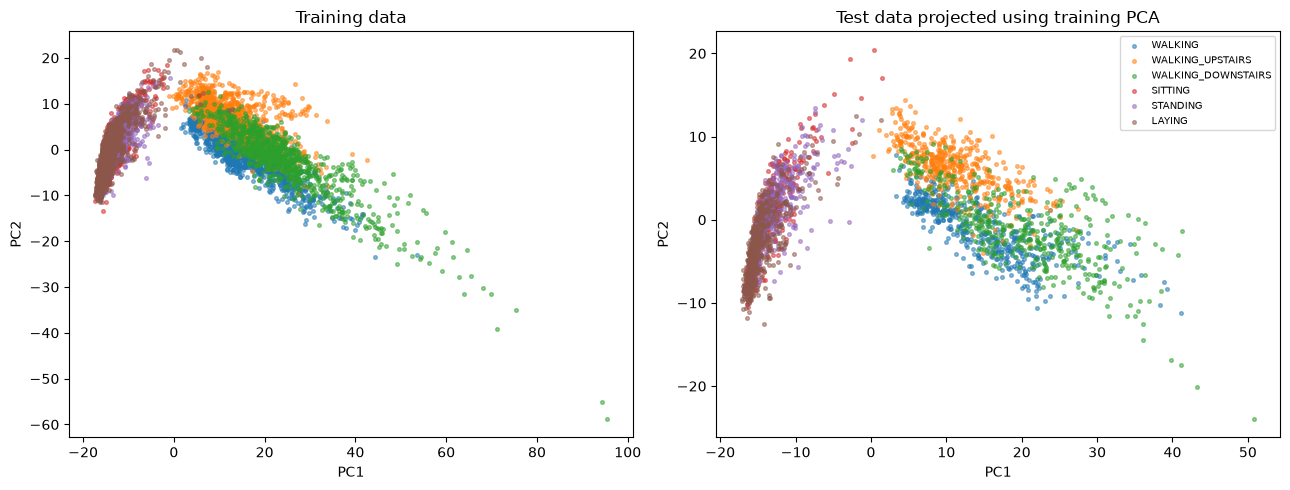

In [9]:
activity_names = dict(zip(activities["Label"], activities["Activity"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for activity in activities["Label"]:
    train_mask = y_train == activity
    test_mask = y_test == activity
    axes[0].scatter(X_train_pca2[train_mask, 0], X_train_pca2[train_mask, 1],
                    s=7, alpha=0.5, label=activity_names[activity])
    axes[1].scatter(X_test_pca2[test_mask, 0], X_test_pca2[test_mask, 1],
                    s=7, alpha=0.5, label=activity_names[activity])
axes[0].set_title("Training data")
axes[1].set_title("Test data projected using training PCA")
for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pca_two_components.png", dpi=150)
plt.show()

## 9. Visualize three components

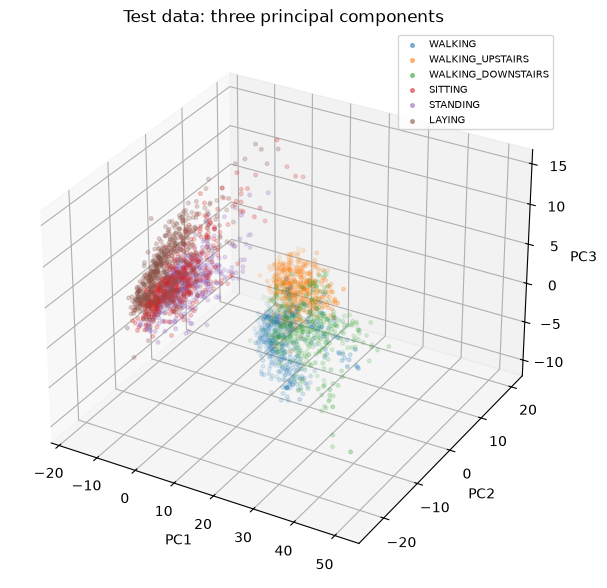

In [10]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")
for activity in activities["Label"]:
    mask = y_test == activity
    ax.scatter(X_test_pca3[mask, 0], X_test_pca3[mask, 1], X_test_pca3[mask, 2],
               s=7, alpha=0.5, label=activity_names[activity])
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("Test data: three principal components")
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pca_three_components.png", dpi=150)
plt.show()

## 10. Read the PCA results
Explained variance measures retained variation, not classification accuracy. Report the variance retained by two and three components, and the number needed for 90%.

Two or three components make readable plots, while clustering can retain more components to preserve more information. The K-Means notebook uses scikit-learn PCA retaining 90% variance before fitting its clusters. Here the covariance/eigenvalue calculation shows how PCA works from scratch.

In this run, the first two components retain **57.36%** of training variance, and three retain **60.17%**. **63 components** are needed to reach at least 90% variance. These percentages measure retained variance rather than prediction accuracy.